In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import wordcloud

nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/ghazalehzehtab/nltk_data...


True

In [16]:
from textblob import TextBlob
from tensorflow.keras.preprocessing.text import Tokenizer
from nltk.sentiment.util import *

In [17]:

trump_df = pd.read_csv(r"Data/hashtag_donaldtrump.csv",lineterminator='\n')

trump_df.head(10)

,created_at,tweet_id,tweet,likes,retweet_count,source,user_id,user_name,user_screen_name,user_description,...,user_followers_count,user_location,lat,long,city,country,continent,state,state_code,collected_at
0,2020-10-15 00:00:01,1.316529e+18,#Elecciones2020 | En #Florida: #JoeBiden dice ...,0.0,0.0,TweetDeck,3.606665e+08,El Sol Latino News,elsollatinonews,🌐 Noticias de interés para latinos de la costa...,...,1860.0,"Philadelphia, PA / Miami, FL",25.774270,-80.193660,NaN,United States of America,North America,Florida,FL,2020-10-21 00:00:00
1,2020-10-15 00:00:01,1.316529e+18,"Usa 2020, Trump contro Facebook e Twitter: cop...",26.0,9.0,Social Mediaset,3.316176e+08,Tgcom24,MediasetTgcom24,Profilo ufficiale di Tgcom24: tutte le notizie...,...,1067661.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:00.373216530
2,2020-10-15 00:00:02,1.316529e+18,"#Trump: As a student I used to hear for years,...",2.0,1.0,Twitter Web App,8.436472e+06,snarke,snarke,"Will mock for food! Freelance writer, blogger,...",...,1185.0,Portland,45.520247,-122.674195,Portland,United States of America,North America,Oregon,OR,2020-10-21 00:00:00.746433060
3,2020-10-15 00:00:02,1.316529e+18,2 hours since last tweet from #Trump! Maybe he...,0.0,0.0,Trumpytweeter,8.283556e+17,Trumpytweeter,trumpytweeter,"If he doesn't tweet for some time, should we b...",...,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:01.119649591
4,2020-10-15 00:00:08,1.316529e+18,You get a tie! And you get a tie! #Trump ‘s ra...,4.0,3.0,Twitter for iPhone,4.741380e+07,Rana Abtar - رنا أبتر,Ranaabtar,"Washington Correspondent, Lebanese-American ,c...",...,5393.0,Washington DC,38.894992,-77.036558,Washington,United States of America,North America,District of Columbia,DC,2020-10-21 00:00:01.492866121
5,2020-10-15 00:00:17,1.316529e+18,@CLady62 Her 15 minutes were over long time ag...,2.0,0.0,Twitter for Android,1.138416e+09,Farris Flagg,FarrisFlagg,#BidenHarris2020 #JoeBiden2020 #KamalaHarrisFo...,...,2363.0,"Perris,California",33.782519,-117.228648,NaN,United States of America,North America,California,CA,2020-10-21 00:00:01.866082651
6,2020-10-15 00:00:17,1.316529e+18,@richardmarx Glad u got out of the house! DICK...,0.0,0.0,Twitter for iPhone,7.674018e+17,Michael Wilson,wilsonfire9,NaN,...,75.0,"Powell, TN",NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:02.239299182
7,2020-10-15 00:00:18,1.316529e+18,@DeeviousDenise @realDonaldTrump @nypost There...,0.0,0.0,Twitter for iPhone,9.007611e+17,Stacey Gulledge 🇺🇸 Patriot ♥️ KAG 🙏 👮‍♀️♥️,sm_gulledge,"Patriot, Wife, “Shaken not Stirred” Mom of two...",...,766.0,"Ohio, USA",40.225357,-82.688140,NaN,United States of America,North America,Ohio,OH,2020-10-21 00:00:02.612515712
8,2020-10-15 00:00:20,1.316529e+18,One of the single most effective remedies to e...,0.0,0.0,Twitter Web App,5.404769e+08,Jamieo,jamieo33,"Don't know what I am. Can lean left and right,...",...,151.0,"Pennsylvania, USA",40.969989,-77.727883,NaN,United States of America,North America,Pennsylvania,PA,2020-10-21 00:00:02.985732243
9,2020-10-15 00:00:21,1.316529e+18,#Election2020 #Trump \n#FreedomOfSpeech https:...,0.0,0.0,Twitter Web App,1.305533e+18,Johnny Quest,JohnnyQuest22,Independent\n\nWhat is your American Dream?\nT...,...,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:03.358948773


In [18]:
biden_df = pd.read_csv(r"Data/hashtag_joebiden.csv",lineterminator='\n')
biden_df.head(10)

,created_at,tweet_id,tweet,likes,retweet_count,source,user_id,user_name,user_screen_name,user_description,...,user_followers_count,user_location,lat,long,city,country,continent,state,state_code,collected_at
0,2020-10-15 00:00:01,1.316529e+18,#Elecciones2020 | En #Florida: #JoeBiden dice ...,0.0,0.0,TweetDeck,3.606665e+08,El Sol Latino News,elsollatinonews,🌐 Noticias de interés para latinos de la costa...,...,1860.0,"Philadelphia, PA / Miami, FL",25.774270,-80.193660,NaN,United States of America,North America,Florida,FL,2020-10-21 00:00:00
1,2020-10-15 00:00:18,1.316529e+18,#HunterBiden #HunterBidenEmails #JoeBiden #Joe...,0.0,0.0,Twitter for iPad,8.099044e+08,Cheri A. 🇺🇸,Biloximeemaw,"Locked and loaded Meemaw. Love God, my family ...",...,6628.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:00.517827283
2,2020-10-15 00:00:20,1.316529e+18,@IslandGirlPRV @BradBeauregardJ @MeidasTouch T...,0.0,0.0,Twitter Web App,3.494182e+09,Flag Waver,Flag_Wavers,NaN,...,1536.0,Golden Valley Arizona,46.304036,-109.171431,NaN,United States of America,North America,Montana,MT,2020-10-21 00:00:01.035654566
3,2020-10-15 00:00:21,1.316529e+18,@chrislongview Watching and setting dvr. Let’s...,0.0,0.0,Twitter for iPhone,8.242596e+17,Michelle Ferg,MichelleFerg4,NaN,...,27.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:01.553481849
4,2020-10-15 00:00:22,1.316529e+18,#censorship #HunterBiden #Biden #BidenEmails #...,1.0,0.0,Twitter Web App,1.032807e+18,the Gold State,theegoldstate,A Silicon Valley #independent #News #Media #St...,...,390.0,"California, USA",36.701463,-118.755997,NaN,United States of America,North America,California,CA,2020-10-21 00:00:02.071309132
5,2020-10-15 00:00:23,1.316529e+18,"""IS THIS WRONG??!!"" Cory Booker's BRILLIANT Fi...",0.0,0.0,Twitter Web App,3.057279e+08,Dose of Dissonance,Dose_Dissonance,YOUTUBE CHANNEL: https://t.co/EFnKm5gnvV MERCH...,...,4622.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:02.589136415
6,2020-10-15 00:00:25,1.316529e+18,"In 2020, #NYPost is being #censorship #CENSORE...",0.0,0.0,Twitter for iPhone,1.994033e+07,Change Illinois | Biden will increase taxes by...,changeillinois,"Illinois, home of Lincoln and Reagan, used to ...",...,1397.0,"Chicago, Illinois",41.875562,-87.624421,Chicago,United States of America,North America,Illinois,IL,2020-10-21 00:00:03.106963698
7,2020-10-15 00:00:31,1.316529e+18,►► Tell Politicians to STICK IT with this FREE...,0.0,0.0,Freebie-Depot,1.030832e+08,🆓 Freebie Depot,FreebieDepot,Free Stuff - No Fluff! Get all kinds of FREE ...,...,6402.0,USA - Land of the FREE!,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:03.624790981
8,2020-10-15 00:00:36,1.316529e+18,#Biden https://t.co/qMs0PmUev5,0.0,0.0,Twitter Web App,1.272568e+18,Kenneth,Kennethuteliv,NaN,...,103.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:04.142618264
9,2020-10-15 00:00:41,1.316529e+18,Proof Bidens are crooked. Twitter will suspen...,1.0,1.0,Twitter for Android,1.275659e+18,Jake Rivendale,JakeRivendale,NaN,...,80.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:04.660445547


In [19]:
print(trump_df.info())

print(biden_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970919 entries, 0 to 970918
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   created_at            970919 non-null  object 
 1   tweet_id              970919 non-null  float64
 2   tweet                 970919 non-null  object 
 3   likes                 970919 non-null  float64
 4   retweet_count         970919 non-null  float64
 5   source                970043 non-null  object 
 6   user_id               970919 non-null  float64
 7   user_name             970897 non-null  object 
 8   user_screen_name      970919 non-null  object 
 9   user_description      869651 non-null  object 
 10  user_join_date        970919 non-null  object 
 11  user_followers_count  970919 non-null  float64
 12  user_location         675957 non-null  object 
 13  lat                   445719 non-null  float64
 14  long                  445719 non-null  float64
 15  

In [21]:
trump_df['Candidate']= 'Trump'
biden_df['Candidate']= 'Biden'

In [22]:
data_mixed = pd.concat([trump_df,biden_df])
data_mixed.sort_values(by='created_at')
data_mixed.head()

,created_at,tweet_id,tweet,likes,retweet_count,source,user_id,user_name,user_screen_name,user_description,...,user_location,lat,long,city,country,continent,state,state_code,collected_at,Candidate
0,2020-10-15 00:00:01,1.316529e+18,#Elecciones2020 | En #Florida: #JoeBiden dice ...,0.0,0.0,TweetDeck,3.606665e+08,El Sol Latino News,elsollatinonews,🌐 Noticias de interés para latinos de la costa...,...,"Philadelphia, PA / Miami, FL",25.774270,-80.193660,NaN,United States of America,North America,Florida,FL,2020-10-21 00:00:00,Trump
1,2020-10-15 00:00:01,1.316529e+18,"Usa 2020, Trump contro Facebook e Twitter: cop...",26.0,9.0,Social Mediaset,3.316176e+08,Tgcom24,MediasetTgcom24,Profilo ufficiale di Tgcom24: tutte le notizie...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:00.373216530,Trump
2,2020-10-15 00:00:02,1.316529e+18,"#Trump: As a student I used to hear for years,...",2.0,1.0,Twitter Web App,8.436472e+06,snarke,snarke,"Will mock for food! Freelance writer, blogger,...",...,Portland,45.520247,-122.674195,Portland,United States of America,North America,Oregon,OR,2020-10-21 00:00:00.746433060,Trump
3,2020-10-15 00:00:02,1.316529e+18,2 hours since last tweet from #Trump! Maybe he...,0.0,0.0,Trumpytweeter,8.283556e+17,Trumpytweeter,trumpytweeter,"If he doesn't tweet for some time, should we b...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21 00:00:01.119649591,Trump
4,2020-10-15 00:00:08,1.316529e+18,You get a tie! And you get a tie! #Trump ‘s ra...,4.0,3.0,Twitter for iPhone,4.741380e+07,Rana Abtar - رنا أبتر,Ranaabtar,"Washington Correspondent, Lebanese-American ,c...",...,Washington DC,38.894992,-77.036558,Washington,United States of America,North America,District of Columbia,DC,2020-10-21 00:00:01.492866121,Trump


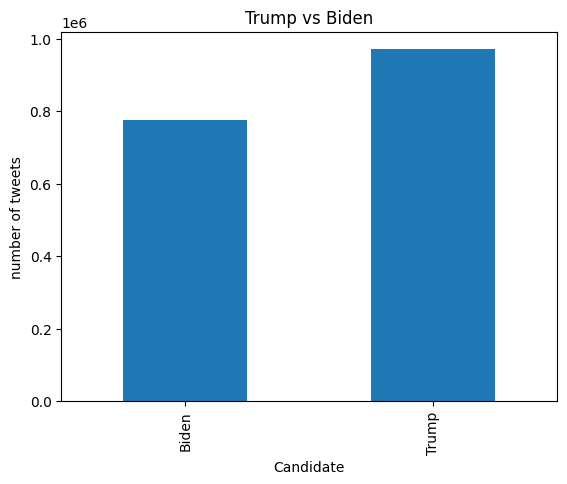

In [23]:
data_mixed.groupby('Candidate')['tweet'].count().plot.bar()
plt.ylabel('number of tweets')
plt.title('Trump vs Biden')
plt.show()

In [24]:
data_mixed['country']= data_mixed['country'].replace({"United States of America":"US","United States":"US"})

In [25]:
data_mixed.country.value_counts()

country
US                          394400
United Kingdom               58051
India                        40091
Germany                      35379
France                       35299
                             ...  
Mali                             2
Northern Mariana Islands         1
Saint Lucia                      1
Lesotho                          1
East Timor                       1
Name: count, Length: 188, dtype: int64

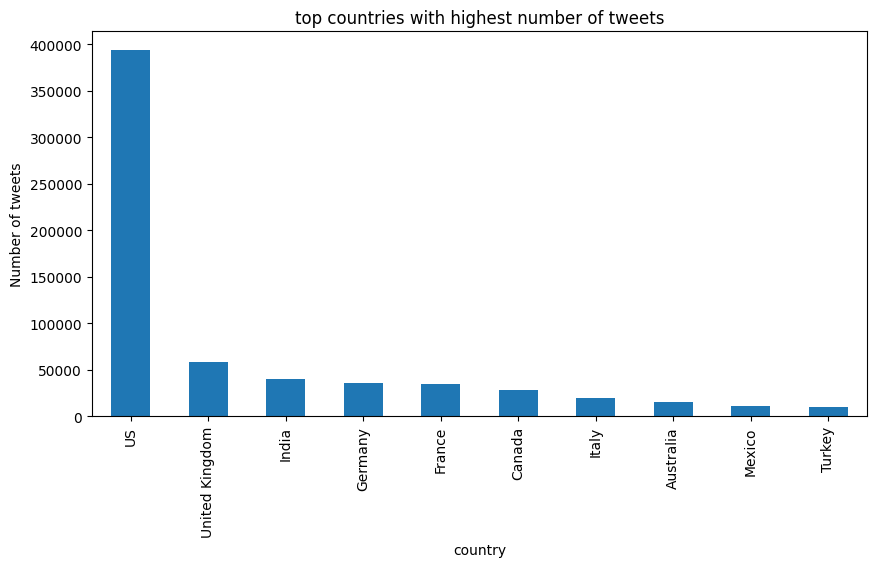

In [26]:
plt.figure(figsize=(10,5))
data_mixed.groupby('country')['tweet'].count().sort_values(ascending=False).head(10).plot.bar()
plt.ylabel('Number of tweets')
plt.title('top countries with highest number of tweets')
plt.show()

In [28]:
top10countries = data_mixed.groupby('country')['tweet'].count().sort_values(ascending=False).head(10).index.tolist()
tweet_df = data_mixed.groupby(['country','Candidate'])['tweet'].count().reset_index()
tweet_df = tweet_df[tweet_df['country'].isin(top10countries)]
tweet_df

,country,Candidate,tweet
16,Australia,Biden,5534
17,Australia,Trump,9365
54,Canada,Biden,10809
55,Canada,Trump,16996
112,France,Biden,14610
113,France,Trump,20689
118,Germany,Biden,12761
119,Germany,Trump,22618
146,India,Biden,21532
147,India,Trump,18559


In [29]:
top10states = data_mixed.groupby('state')['tweet'].count().sort_values(ascending=False).head(10).index.tolist()
state_df = data_mixed.groupby(['state','Candidate'])['tweet'].count().reset_index()
state_df = state_df[state_df['state'].isin(top10states)]
state_df

,state,Candidate,tweet
206,California,Biden,25817
207,California,Trump,31149
349,District of Columbia,Biden,7055
350,District of Columbia,Trump,9684
386,England,Biden,16743
387,England,Trump,24111
410,Florida,Biden,13284
411,Florida,Trump,16568
518,Ile-de-France,Biden,7001
519,Ile-de-France,Trump,9393


# Sentiment Analysis

### Cleaning


In [30]:
lm = WordNetLemmatizer()


def clean(text):
    text = str(text).lower()
    text = re.sub('[^a-z]',' ',str(text))
    text = text.split()
    text = [lm.lemmatize(j) for j in text if j not in set(stopwords.words('english'))]
    text = ' '.join(str(k) for k in text)
    return text

In [31]:
def getsubjectivity(text):
    return TextBlob(text).sentiment.subjectivity
def getpolarity(text):
    return TextBlob(text).sentiment.polarity
def getAnalysis(score):
    if score <0:
        return 'negative'
    elif score == 0:
        return 'neutral'
    else:
        return 'positive'

### Trump

In [32]:
trump_tweets = data_mixed.query('(Candidate == "Trump")').sort_values('user_followers_count',ascending=False).drop_duplicates(['user_name'])[['tweet','country']]
trump_tweets = trump_tweets.dropna().loc[trump_tweets.country =='US']
trump_tweets.reset_index(inplace = True ,drop =True)
trump_tweets

,tweet,country
0,"Without a doubt, the #FourSeasons debacle is t...",US
1,"President Donald #Trump’s youngest daughter, T...",US
2,Woah. Have you read this article?\n\nAll the p...,US
3,The latest episode of #SNL tackled #DonaldTrum...,US
4,🇺🇸 #Decision2020: @JoeBiden firmará una serie ...,US
...,...,...
45518,@NBCNews You wanted it over by election nights...,US
45519,"Even if #Trump DID win this election, he would...",US
45520,"Twisted, pressed &amp; curled almost empty too...",US
45521,#Election2020\n#USElectionResults2020\n#Donald...,US


In [33]:
trump_tweets['cleantext'] = trump_tweets['tweet'].apply(clean)


In [34]:
trump_tweets['subjectivity'] = trump_tweets['cleantext'].apply(getsubjectivity)

In [35]:
trump_tweets['polarity'] = trump_tweets['cleantext'].apply(getpolarity)

In [36]:
trump_tweets['analysis'] = trump_tweets['polarity'].apply(getAnalysis)

In [38]:
trump_tweets.head(15)

,tweet,country,cleantext,subjectivity,polarity,analysis
0,"Without a doubt, the #FourSeasons debacle is t...",US,without doubt fourseasons debacle best part do...,0.483333,0.333333,positive
1,"President Donald #Trump’s youngest daughter, T...",US,president donald trump youngest daughter tiffa...,0.000000,0.000000,neutral
2,Woah. Have you read this article?\n\nAll the p...,US,woah read article president debt donald trump ...,0.000000,0.000000,neutral
3,The latest episode of #SNL tackled #DonaldTrum...,US,latest episode snl tackled donaldtrump loss co...,0.800000,-0.033333,negative
4,🇺🇸 #Decision2020: @JoeBiden firmará una serie ...,US,decision joebiden firmar una serie de rdenes e...,0.000000,0.000000,neutral
5,#Trump Anuncia conferencia de prensa en Filade...,US,trump anuncia conferencia de prensa en filadel...,0.000000,0.000000,neutral
6,"LIVE: President Donald Trump in Erie, PA #Penn...",US,live president donald trump erie pa pennsylvan...,0.500000,0.136364,positive
7,#trump wants to throw out military ballots? W...,US,trump want throw military ballot bone spur,0.100000,-0.100000,negative
8,.@rauldemolina habló del panorama de las elecc...,US,rauldemolina habl del panorama de la eleccione...,0.000000,0.000000,neutral
9,POLL: Trump's Approval Hits 52% https://t.co/0...,US,poll trump approval hit http co ahwqcmm electi...,0.000000,0.000000,neutral


In [39]:
trump_tweets.analysis.value_counts(normalize=True)*100

analysis
neutral     45.627485
positive    34.389210
negative    19.983305
Name: proportion, dtype: float64

### Biden

In [40]:
biden_tweets = data_mixed.query('(Candidate == "Biden")').sort_values('user_followers_count',ascending=False).drop_duplicates(['user_name'])[['tweet','country']]
biden_tweets = biden_tweets.dropna().loc[biden_tweets.country =='US']
biden_tweets.reset_index(inplace = True ,drop =True)
biden_tweets

,tweet,country
0,#JoeBiden is enlisting A-list star power to he...,US
1,While we were campaigning across battleground ...,US
2,The big fight TODAY!!!!! @realDonaldTrump vs #...,US
3,News outlets have projected that #JoeBiden has...,US
4,"During his victory speech, #JoeBiden said he u...",US
...,...,...
57545,46th President of The Unites States! Congratul...,US
57546,Biden IS going to win tonight. #biden #Electio...,US
57547,All 238k deaths recorded in the United States ...,US
57548,Joe Biden'in başa gelmesi bizim bence işimize ...,US


In [41]:
biden_tweets['cleantext'] = biden_tweets['tweet'].apply(clean)

biden_tweets['subjectivity'] = biden_tweets['cleantext'].apply(getsubjectivity)
biden_tweets['polarity'] = biden_tweets['cleantext'].apply(getpolarity)
biden_tweets['analysis'] = biden_tweets['polarity'].apply(getAnalysis)
biden_tweets.head(15)

,tweet,country,cleantext,subjectivity,polarity,analysis
0,#JoeBiden is enlisting A-list star power to he...,US,joebiden enlisting list star power help close ...,0.000,0.0000,neutral
1,While we were campaigning across battleground ...,US,campaigning across battleground state ran grea...,0.750,0.8000,positive
2,The big fight TODAY!!!!! @realDonaldTrump vs #...,US,big fight today realdonaldtrump v joebiden got...,0.100,0.0000,neutral
3,News outlets have projected that #JoeBiden has...,US,news outlet projected joebiden secured elector...,0.000,0.0000,neutral
4,"During his victory speech, #JoeBiden said he u...",US,victory speech joebiden said understood trump ...,0.750,-0.7500,negative
5,Los nueve minutos de colorida celebración tras...,US,los nueve minutos de colorida celebraci n tras...,0.000,0.0000,neutral
6,#AHORA Primer Ministro Israel reconoce a #Bide...,US,ahora primer ministro israel reconoce biden gr...,0.000,0.0000,neutral
7,Biden updated that bio quicker than a Neo 😭😭✊🏽...,US,biden updated bio quicker neo joebiden election,0.000,0.0000,neutral
8,Wonderful speeches tonight by President and Vi...,US,wonderful speech tonight president vice presid...,0.680,0.5225,positive
9,.@rauldemolina habló del panorama de las elecc...,US,rauldemolina habl del panorama de la eleccione...,0.000,0.0000,neutral


In [42]:
biden_tweets[biden_tweets["polarity"]>0]

,tweet,country,cleantext,subjectivity,polarity,analysis
1,While we were campaigning across battleground ...,US,campaigning across battleground state ran grea...,0.750000,0.800000,positive
8,Wonderful speeches tonight by President and Vi...,US,wonderful speech tonight president vice presid...,0.680000,0.522500,positive
11,.@JudicialWatch President @TomFitton with @Rud...,US,judicialwatch president tomfitton rudygiuliani...,0.325000,0.175000,positive
15,VERY IMPORTANT podcast this week: https://t.co...,US,important podcast week http co hcrxh daan dr v...,0.600000,0.150000,positive
20,Is great that we will have a President that wi...,US,great president bring peace lead moment darkne...,0.750000,0.800000,positive
...,...,...,...,...,...,...
57532,@KaceyonFox7 @fox7austin I support any movemen...,US,kaceyonfox fox austin support movement involve...,1.000000,0.500000,positive
57534,Can you guys believe what #JoeBiden did in con...,US,guy believe joebiden concert son hunterbiden a...,0.900000,0.200000,positive
57538,@FLOTUS Time to get a new twitter handle.. BYE...,US,flotus time get new twitter handle bye bye tru...,0.454545,0.136364,positive
57543,HOLY FUCKING SHIT IMMA BE ABLE TO KEEP MY RIGH...,US,holy fucking shit imma able keep right im sobb...,0.740179,0.346429,positive
